# US Universe Screening (Dynamic Top-Down Inputs)

* Edit any input in **Cell 1** (risk-free rate, volatility cap, return window, sector caps, active weight cutoff, or drawdown limit) and run all cells.
* Every accepted stock list, table, funnel count, and chart below is built dynamically from those inputs — nothing is hardcoded.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import datetime, json, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.ticker import PercentFormatter

COL_NAVY = '#1F4E79'
COL_STEEL = '#5B8DBE'
COL_TEAL = '#1E7166'
COL_CRIMSON = '#B03A2E'
COL_SLATE = '#8C96A0'
COL_AMBER = '#B87333'
COL_PLUM = '#5B4B8A'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.5f}'.format

# ==============================================================================
# TOP-LEVEL USER INPUTS (Change any value here and run all cells below)
# ==============================================================================
START_DATE = '2021-01-01'
END_DATE = '2025-12-31'
TRAIN_END = '2023-12-31'
N = 252

rf_base = 0.03           # Unscreened benchmark risk-free rate
DRAWDOWN_LIMIT = 0.10    # Maximum drawdown comfort limit

rf_screen = 0.0434       # Stage 2: minimum annual return E(r) > rf_screen
MAX_VOL = 0.32           # Stage 3: maximum annual SD <= MAX_VOL
MIN_MEAN = 0.12          # Stage 4: lower annual return bound E(r) >= MIN_MEAN
MAX_MEAN = 0.25          # Stage 4: upper annual return bound E(r) <= MAX_MEAN
MIN_ACTIVE_WT = 0.01     # Stage 5: active frontier weight cutoff (w >= MIN_ACTIVE_WT)
# ==============================================================================

def load_universe():
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'stock_universe.csv'
        if fp.exists():
            df = pd.read_csv(fp)
            df = df[df['Included'].astype(str).str.lower() == 'true'].copy()
            return df['Ticker'].tolist(), dict(zip(df['Ticker'], df['Business']))
    raise FileNotFoundError('Could not find stock_universe.csv')

def fetch_price_series(ticker, start=START_DATE, end=END_DATE):
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'data' / f'{ticker}_{start}_{end}.csv'
        if fp.exists():
            df = pd.read_csv(fp, parse_dates=['Date']).sort_values('Date')
            col = 'Adj Close' if 'Adj Close' in df.columns else 'Close'
            return pd.Series(pd.to_numeric(df[col]).to_numpy(), index=df['Date'], name=ticker).loc[start:end]
    p1 = int(pd.Timestamp(start, tz='UTC').timestamp())
    p2 = int((pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1)).timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={p1}&period2={p2}&interval=1d'
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=15) as resp:
        res = json.loads(resp.read().decode())['chart']['result'][0]
    dates = [datetime.datetime.fromtimestamp(x, tz=datetime.timezone.utc).strftime('%Y-%m-%d') for x in res['timestamp']]
    s = pd.Series(pd.to_numeric(res['indicators']['adjclose'][0]['adjclose'], errors='coerce'),
                  index=pd.to_datetime(dates), name=ticker).dropna()
    return s[~s.index.duplicated()].sort_index().loc[start:end]

def load_prices(ticker_list, start=START_DATE, end=END_DATE):
    with ThreadPoolExecutor(max_workers=8) as ex:
        return pd.concat(list(ex.map(lambda t: fetch_price_series(t, start, end), ticker_list)), axis=1).dropna()

US_UNIVERSE, UNIVERSE_SECTORS = load_universe()
raw_prices = load_prices(US_UNIVERSE, START_DATE, END_DATE)
raw_rets = raw_prices.pct_change().dropna()
raw_train = raw_rets.loc[:TRAIN_END]
raw_test = raw_rets.loc[raw_rets.index > pd.Timestamp(TRAIN_END)]

all_prices, all_rets, all_train, all_test = raw_prices, raw_rets, raw_train, raw_test
sp_valid = pd.DataFrame({
    'Symbol': US_UNIVERSE,
    'GICS Sector': [UNIVERSE_SECTORS[t] for t in US_UNIVERSE],
    'GICS Sub-Industry': [UNIVERSE_SECTORS[t] for t in US_UNIVERSE],
    'Mean': [raw_train[t].mean() * N for t in US_UNIVERSE],
    'SD': [raw_train[t].std(ddof=1) * np.sqrt(N) for t in US_UNIVERSE],
})
sp_valid['Sharpe'] = (sp_valid['Mean'] - rf_screen) / sp_valid['SD']

print(f'Loaded {len(sp_valid)} stocks from stock_universe.csv')
print(f'Active Rules -> E(r) > {rf_screen:.2%}, SD <= {MAX_VOL:.0%}, {MIN_MEAN:.0%} <= E(r) <= {MAX_MEAN:.0%}, Min weight >= {MIN_ACTIVE_WT:.1%}')

Loaded 59 stocks from stock_universe.csv
Active Rules -> E(r) > 4.34%, SD <= 32%, 12% <= E(r) <= 25%, Min weight >= 1.0%


## Unscreened Sector Pool Baseline

* Evaluates the broad unscreened sector pool at `rf_base` without volatility or return-range filters.
* Shows how an unscreened pool concentrates in past winners and increases out-of-sample drawdown.

In [2]:
# 1. Calculate unscreened sector pool G & P and out-of-sample drawdown
def solve_gp(cols, rfr):
    tr = raw_train[cols]
    mv = (tr.mean() * N).to_numpy()
    cm = (tr.cov() * N).to_numpy()
    m = len(cols)
    w0 = np.ones(m) / m  # Start SLSQP optimizer at equal weights
    bnds = [(0, 1)] * m
    eq = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]  # Full investment constraint: weights sum to 100%
    wg = minimize(lambda w: w @ cm @ w, w0, method='SLSQP', bounds=bnds, constraints=eq, options={'ftol': 1e-12, 'maxiter': 2000}).x  # Solve Global Minimum Variance portfolio G
    wp = minimize(lambda w: -(w @ mv - rfr) / np.sqrt(w @ cm @ w), w0, method='SLSQP', bounds=bnds, constraints=eq, options={'ftol': 1e-12, 'maxiter': 2000}).x  # Solve Maximum Sharpe portfolio P
    return mv, cm, wg, wp, float(wg @ mv), float(np.sqrt(wg @ cm @ wg)), float(wp @ mv), float(np.sqrt(wp @ cm @ wp))

mu_u, cov_u, wG_u, wP_u, g_u_m, g_u_s, p_u_m, p_u_s = solve_gp(US_UNIVERSE, rf_base)
k_u = len(US_UNIVERSE)
ab_u = (p_u_m - rf_base) / (p_u_s ** 2)  # Risk aversion cutoff where unconstrained y* reaches 100%

r_u_oos = pd.Series(all_test.to_numpy() @ wP_u, index=all_test.index)
w_u_curve = (1.0 + r_u_oos).cumprod()
dd_u_series = (w_u_curve / w_u_curve.cummax() - 1.0) * 100  # Compute running peak-to-trough percentage drawdown
dd_u_min = float(dd_u_series.min()) / 100.0

In [3]:
# 2. Output unscreened baseline metrics and active holdings
baseline_tbl = pd.DataFrame([
    {'Portfolio': f'Unscreened Pool G ({k_u} stocks)', 'Mean': g_u_m, 'SD': g_u_s, 'Sharpe': (g_u_m - rf_base) / g_u_s, 'Cutoff A': np.nan},
    {'Portfolio': f'Unscreened Pool P ({k_u} stocks)', 'Mean': p_u_m, 'SD': p_u_s, 'Sharpe': (p_u_m - rf_base) / p_u_s, 'Cutoff A': ab_u},
])
display(baseline_tbl)  # Display formatted summary table

held_u = pd.DataFrame({'GICS Sub-Industry': [UNIVERSE_SECTORS[t] for t in US_UNIVERSE], 'P Weight': wP_u, 'Mean': mu_u, 'SD': np.sqrt(np.diag(cov_u))}, index=US_UNIVERSE)
held_u = held_u[held_u['P Weight'] > 1e-3].sort_values('P Weight', ascending=False)
display(held_u)  # Display formatted summary table
print(f'Active holdings: {len(held_u)} | Top stock: {held_u.index[0]} ({held_u.iloc[0]["P Weight"]:.2%}) | Cutoff A: {ab_u:.3f} | OOS MaxDD: {dd_u_min:.2%}')

,Portfolio,Mean,SD,Sharpe,Cutoff A
0,Unscreened Pool G (59 stocks),0.08793,0.11368,0.50964,NaN
1,Unscreened Pool P (59 stocks),0.36084,0.18231,1.81476,9.95447


,GICS Sub-Industry,P Weight,Mean,SD
MPC,Oil refining,0.31919,0.51742,0.32945
WM,Waste services,0.16439,0.18222,0.18221
ABBV,Pharmaceuticals,0.12574,0.19257,0.20711
AVGO,Semiconductors,0.10934,0.40512,0.32852
NVDA,Semiconductors,0.09129,0.58465,0.53001
NOC,Defense,0.07376,0.20246,0.24975
ED,Utilities,0.07010,0.14004,0.19104
EQT,Natural gas production,0.02445,0.49310,0.50508
XOM,Integrated energy,0.01330,0.38471,0.30199
COST,Warehouse retail,0.00844,0.22854,0.23902


Active holdings: 10 | Top stock: MPC (31.92%) | Cutoff A: 9.954 | OOS MaxDD: -15.88%


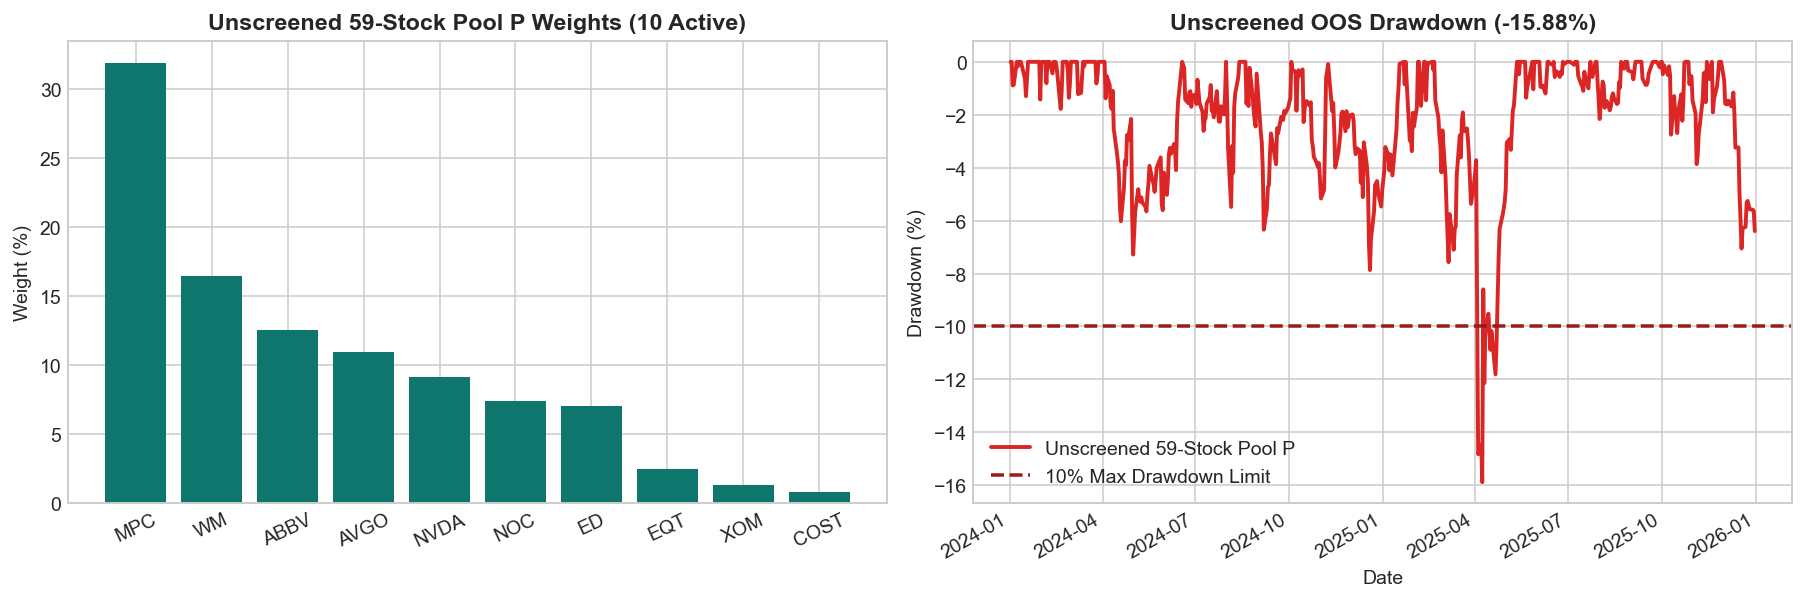

In [4]:
# 3. Draw unscreened weights and OOS drawdown
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))  # Create side-by-side two-panel figure
axes[0].bar(held_u.index, held_u['P Weight'] * 100, color='#0F766E')  # Plot bar chart on left panel
axes[0].set(ylabel='Weight (%)', title=f'Unscreened {k_u}-Stock Pool P Weights ({len(held_u)} Active)')  # Configure left/top panel labels and title
axes[0].tick_params(axis='x', rotation=25)

dd_u_series.plot(ax=axes[1], color='#DC2626', lw=2.0, label=f'Unscreened {k_u}-Stock Pool P')  # Plot out-of-sample drawdown curve
axes[1].axhline(-DRAWDOWN_LIMIT * 100, color='#991B1B', linestyle='--', lw=1.8, label=f'{DRAWDOWN_LIMIT:.0%} Max Drawdown Limit')  # Add horizontal reference threshold on right panel
axes[1].set(ylabel='Drawdown (%)', title=f'Unscreened OOS Drawdown ({dd_u_min:.2%})')  # Configure right/bottom panel labels and title
axes[1].legend()
plt.tight_layout(); plt.show()  # Adjust spacing and render chart

## Dynamic Screening Funnel & Accepted Stocks

* Applies your top-level thresholds (`rf_screen`, `MAX_VOL`, `MIN_MEAN`, `MAX_MEAN`, `TOP_PER_SUBIND`, `TOP_PER_SECTOR`, `MIN_ACTIVE_WT`).
* Automatically determines which stocks pass every stage and which stocks earn active weights on the efficient frontier.

In [5]:
# 1. Apply top-level screening rules and derive active frontier stocks dynamically
m_ex = sp_valid['Mean'] > rf_screen
m_vol = m_ex & (sp_valid['SD'] <= MAX_VOL)
m_trim = m_vol & (sp_valid['Mean'] >= MIN_MEAN) & (sp_valid['Mean'] <= MAX_MEAN)

top_per_sector = sp_valid[m_trim].sort_values('Sharpe', ascending=False).copy()
screened_tickers = top_per_sector['Symbol'].tolist()
if len(screened_tickers) < 2:
    raise ValueError(f'Only {len(screened_tickers)} stock(s) passed your screening thresholds. Relax MAX_VOL, MIN_MEAN, or MAX_MEAN in Cell 1.')

_, _, _, w_screen_p, _, _, _, _ = solve_gp(screened_tickers, rf_screen)
active_pairs = sorted([(t, float(w)) for t, w in zip(screened_tickers, w_screen_p) if w >= MIN_ACTIVE_WT], key=lambda x: -x[1])
if len(active_pairs) < 2:
    active_pairs = sorted([(t, float(w)) for t, w in zip(screened_tickers, w_screen_p)], key=lambda x: -x[1])[:2]

SELECTED_TICKERS = [t for t, _ in active_pairs]
k_sel = len(SELECTED_TICKERS)

In [6]:
# 2. Output dynamic screening funnel and accepted stocks
funnel_df = pd.DataFrame([
    {'Filter': 'Raw Universe', 'Rule': f'All {len(sp_valid)} stocks in stock_universe.csv', 'Remaining': len(sp_valid)},
    {'Filter': 'Excess Return', 'Rule': f'E(r) > {rf_screen:.2%}', 'Remaining': int(m_ex.sum())},
    {'Filter': 'Volatility Cap', 'Rule': f'Annual SD <= {MAX_VOL:.0%}', 'Remaining': int(m_vol.sum())},
    {'Filter': 'Return Window', 'Rule': f'{MIN_MEAN:.0%} <= E(r) <= {MAX_MEAN:.0%} & SD <= {MAX_VOL:.0%}', 'Remaining': int(m_trim.sum())},
    {'Filter': f'{k_sel} Accepted Leaders', 'Rule': f'Active weight >= {MIN_ACTIVE_WT:.1%} ({", ".join(SELECTED_TICKERS)})', 'Remaining': k_sel},
])
display(Markdown(f'**Accepted {k_sel} frontier stocks from {len(sp_valid)} ({len(top_per_sector)} screened candidates):** `{", ".join(SELECTED_TICKERS)}`'))
display(funnel_df)
display(top_per_sector[['Symbol', 'GICS Sector', 'Mean', 'SD', 'Sharpe']].reset_index(drop=True))

**Accepted 8 frontier stocks from 59 (18 screened candidates):** `ABBV, NOC, COST, WM, MSFT, IBM, CAT, ORCL`

,Filter,Rule,Remaining
0,Raw Universe,All 59 stocks in stock_universe.csv,59
1,Excess Return,E(r) > 4.34%,49
2,Volatility Cap,Annual SD <= 32%,34
3,Return Window,12% <= E(r) <= 25% & SD <= 32%,18
4,8 Accepted Leaders,"Active weight >= 1.0% (ABBV, NOC, COST, WM, MS...",8


,Symbol,GICS Sector,Mean,SD,Sharpe
0,COST,Warehouse retail,0.22854,0.23902,0.77460
1,WM,Waste services,0.18222,0.18221,0.76188
2,ABBV,Pharmaceuticals,0.19257,0.20711,0.72023
3,MSFT,Software,0.23077,0.27835,0.67315
4,MCD,Restaurants,0.15138,0.16492,0.65473
5,IBM,IT services,0.17942,0.21120,0.64403
6,NOC,Defense,0.20246,0.24975,0.63691
7,CAT,Construction equipment,0.22692,0.29405,0.62411
8,ORCL,Enterprise software,0.22957,0.29983,0.62092
9,UNH,Health insurance,0.17470,0.21675,0.60577


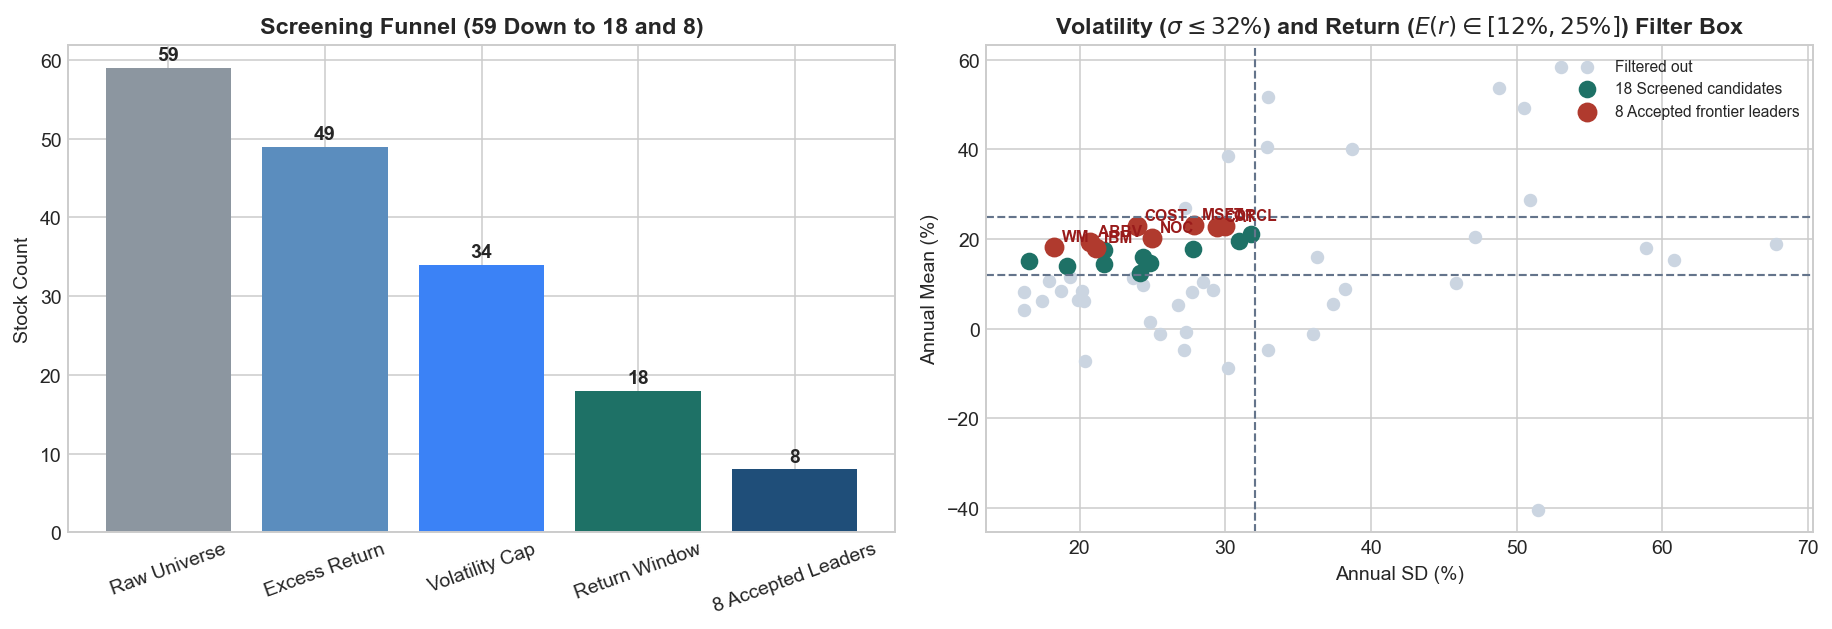

In [7]:
# 3. Draw dynamic funnel counts and risk-return filter box
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
axes[0].bar(funnel_df['Filter'], funnel_df['Remaining'], color=[COL_SLATE, COL_STEEL, '#3B82F6', COL_TEAL, COL_NAVY])
for i, v in enumerate(funnel_df['Remaining']):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')
axes[0].set(ylabel='Stock Count', title=f'Screening Funnel ({len(sp_valid)} Down to {len(top_per_sector)} and {k_sel})')
axes[0].tick_params(axis='x', rotation=20)

sel_rows = sp_valid[sp_valid['Symbol'].isin(SELECTED_TICKERS)]
axes[1].scatter(sp_valid['SD'] * 100, sp_valid['Mean'] * 100, c='#CBD5E1', s=35, label='Filtered out')
axes[1].scatter(top_per_sector['SD'] * 100, top_per_sector['Mean'] * 100, c=COL_TEAL, s=65, label=f'{len(top_per_sector)} Screened candidates')
axes[1].scatter(sel_rows['SD'] * 100, sel_rows['Mean'] * 100, c=COL_CRIMSON, s=85, label=f'{k_sel} Accepted frontier leaders')
for _, r in sel_rows.iterrows():
    axes[1].annotate(r['Symbol'], (r['SD'] * 100, r['Mean'] * 100), xytext=(4, 3), textcoords='offset points', fontsize=8, fontweight='bold', color='#991B1B')
axes[1].axhline(MIN_MEAN * 100, color='#64748B', linestyle='--', lw=1.1)
axes[1].axhline(MAX_MEAN * 100, color='#64748B', linestyle='--', lw=1.1)
axes[1].axvline(MAX_VOL * 100, color='#64748B', linestyle='--', lw=1.1)
axes[1].set(xlabel='Annual SD (%)', ylabel='Annual Mean (%)', title=rf'Volatility ($\sigma \leq {MAX_VOL*100:.0f}\%$) and Return ($E(r) \in [{MIN_MEAN*100:.0f}\%, {MAX_MEAN*100:.0f}\%]$) Filter Box')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Cross-Sector Pair Correlation Search

* Evaluates pairwise correlations across distinct GICS sub-industries in the broad pool (training vs. out-of-sample).

In [8]:
# 1. Calculate pairwise correlations across distinct S&P 500 sub-industries
rows_corr = []
for i, a in enumerate(US_UNIVERSE):
    for b in US_UNIVERSE[i + 1:]:
        if UNIVERSE_SECTORS[a] == UNIVERSE_SECTORS[b]:
            continue
        rows_corr.append({
            'Stock A': a, 'Sub-Industry A': UNIVERSE_SECTORS[a],
            'Stock B': b, 'Sub-Industry B': UNIVERSE_SECTORS[b],
            'Train rho': float(all_train[a].corr(all_train[b])),
            'Test rho': float(all_test[a].corr(all_test[b])),
        })
pair_df = pd.DataFrame(rows_corr).sort_values('Train rho').reset_index(drop=True)
low_pair = pair_df.iloc[0]

In [9]:
# 2. Output lowest cross-sector correlation pairs
print(f'{len(pair_df)} pairs | Lowest training pair: {low_pair["Stock A"]} & {low_pair["Stock B"]} (rho={low_pair["Train rho"]:.4f})')
display(pair_df.head(10))  # Display formatted summary table

1688 pairs | Lowest training pair: CCL & GIS (rho=-0.0824)


,Stock A,Sub-Industry A,Stock B,Sub-Industry B,Train rho,Test rho
0,CCL,Cruise travel,GIS,Packaged food,-0.08239,-0.07003
1,ZM,Communications software,GIS,Packaged food,-0.07655,-0.01435
2,GIS,Packaged food,TSLA,Electric vehicles,-0.07417,-0.08630
3,VLO,Oil refining,CLX,Household products,-0.06889,0.00338
4,MPC,Oil refining,CLX,Household products,-0.06854,0.00812
5,GIS,Packaged food,AMD,Semiconductors,-0.05927,-0.19617
6,OXY,Oil and gas production,CLX,Household products,-0.05366,0.09496
7,GIS,Packaged food,NVDA,Semiconductors,-0.05175,-0.32444
8,ZM,Communications software,HSY,Confectionery,-0.05071,0.02382
9,MRNA,Biotechnology,GIS,Packaged food,-0.04145,0.13881


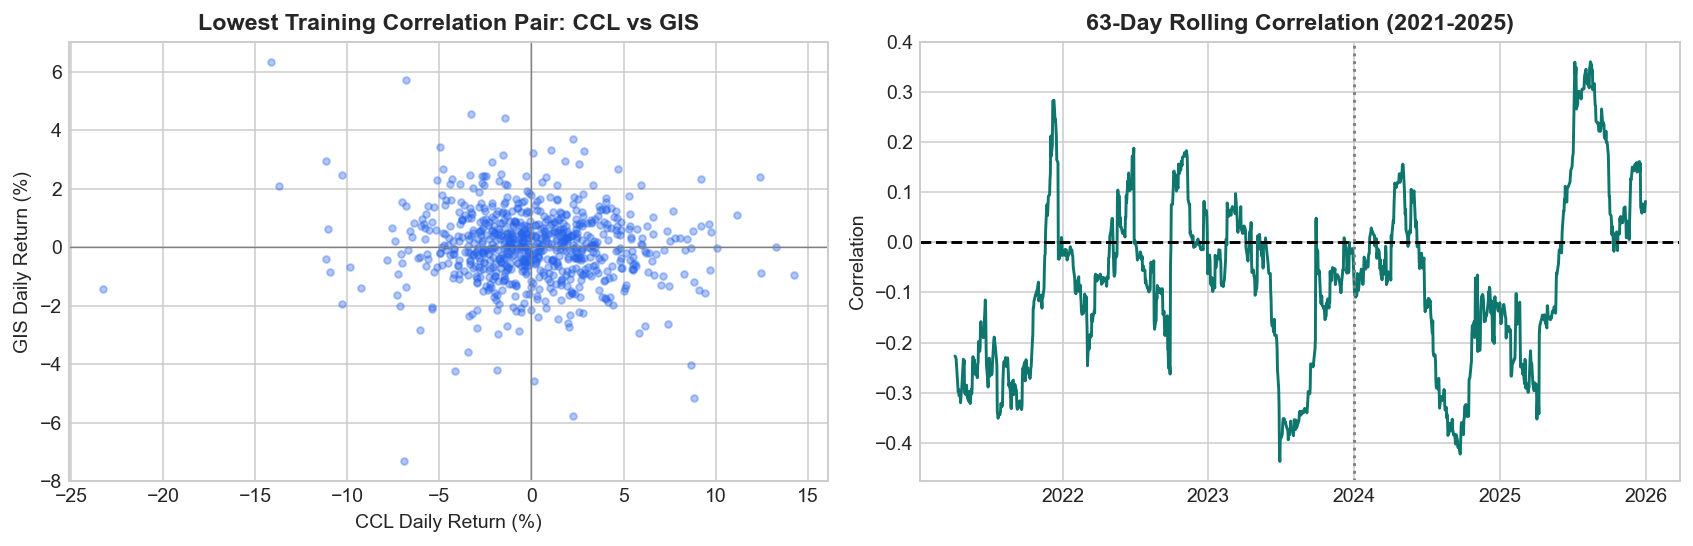

In [10]:
# 3. Draw lowest-correlation pair scatter and 63-day rolling correlation
a, b = low_pair['Stock A'], low_pair['Stock B']
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.0))  # Create side-by-side two-panel figure
axes[0].scatter(all_train[a] * 100, all_train[b] * 100, s=12, alpha=0.35, color='#2563EB')  # Plot individual stocks in risk-return space
axes[0].axhline(0, color='gray', lw=0.7); axes[0].axvline(0, color='gray', lw=0.7)  # Add horizontal reference threshold on left panel
axes[0].set(xlabel=f'{a} Daily Return (%)', ylabel=f'{b} Daily Return (%)', title=f'Lowest Training Correlation Pair: {a} vs {b}')  # Configure left/top panel labels and title
roll = all_rets[a].rolling(63).corr(all_rets[b])  # 63-trading-day (~1 quarter) rolling correlation
axes[1].plot(roll.index, roll, color='#0F766E')  # Plot 63-day rolling correlation over 2021-2025
axes[1].axhline(0, color='black', linestyle='--'); axes[1].axvline(pd.Timestamp(TRAIN_END), color='gray', linestyle=':')  # Add horizontal reference threshold on right panel
axes[1].set(title=f'63-Day Rolling Correlation ({START_DATE[:4]}-{END_DATE[:4]})', ylabel='Correlation')  # Configure right/bottom panel labels and title
plt.tight_layout(); plt.show()  # Adjust spacing and render chart

## Dynamic Frontier & Subset Sensitivity Check

* Evaluates the accepted frontier stocks and compares them against smaller subsets built dynamically from the same screened candidates.

In [11]:
# 1. Solve G & P for the accepted stocks and dynamic comparison subsets
_, _, wG_sel, wP_sel, g_sel_m, g_sel_s, p_sel_m, p_sel_s = solve_gp(SELECTED_TICKERS, rf_screen)

ablation_rows = [{
    'Subset': f'{k_sel}-Stock Accepted Frontier',
    'Tickers': ', '.join(SELECTED_TICKERS),
    'Assets': k_sel,
    'G SD': g_sel_s,
    'P Mean': p_sel_m,
    'P SD': p_sel_s,
    'P Sharpe': (p_sel_m - rf_screen) / p_sel_s,
}]

# Dynamic check 1: drop the 2 lowest-volatility stabilizers (if k_sel >= 4)
if k_sel >= 4:
    sel_sds = raw_train[SELECTED_TICKERS].std(ddof=1) * np.sqrt(N)
    dropped_2 = sel_sds.nsmallest(2).index.tolist()
    reduced_cols = [t for t in SELECTED_TICKERS if t not in dropped_2]
    _, _, _, _, g_r_m, g_r_s, p_r_m, p_r_s = solve_gp(reduced_cols, rf_screen)
    ablation_rows.append({
        'Subset': f'{len(reduced_cols)}-Stock (Without {" & ".join(dropped_2)})',
        'Tickers': ', '.join(reduced_cols),
        'Assets': len(reduced_cols),
        'G SD': g_r_s,
        'P Mean': p_r_m,
        'P SD': p_r_s,
        'P Sharpe': (p_r_m - rf_screen) / p_r_s,
    })

# Dynamic check 2: top-4 highest standalone Sharpe picks across distinct sectors
top4_cols = top_per_sector.sort_values('Sharpe', ascending=False).groupby('GICS Sector').head(1)['Symbol'].head(min(4, len(top_per_sector))).tolist()
if len(top4_cols) >= 2:
    _, _, _, _, g_4_m, g_4_s, p_4_m, p_4_s = solve_gp(top4_cols, rf_screen)
    ablation_rows.append({
        'Subset': f'Top-{len(top4_cols)} Standalone Sharpe Leaders',
        'Tickers': ', '.join(top4_cols),
        'Assets': len(top4_cols),
        'G SD': g_4_s,
        'P Mean': p_4_m,
        'P SD': p_4_s,
        'P Sharpe': (p_4_m - rf_screen) / p_4_s,
    })

ablation_df = pd.DataFrame(ablation_rows)

In [12]:
# 2. Output dynamic subset comparison and accepted P weights
display(ablation_df)  # Display formatted summary table
w_sel_tbl = pd.DataFrame({
    'GICS Sub-Industry': [UNIVERSE_SECTORS[t] for t in SELECTED_TICKERS],
    'G Weight': wG_sel,
    'P Weight': wP_sel,
}, index=SELECTED_TICKERS)
display(w_sel_tbl)  # Display formatted summary table

,Subset,Tickers,Assets,G SD,P Mean,P SD,P Sharpe
0,8-Stock Accepted Frontier,"ABBV, NOC, COST, WM, MSFT, IBM, CAT, ORCL",8,0.13533,0.20556,0.13947,1.16270
1,6-Stock (Without WM & ABBV),"NOC, COST, MSFT, IBM, CAT, ORCL",6,0.15544,0.21380,0.15903,1.07150
2,Top-4 Standalone Sharpe Leaders,"COST, WM, ABBV, MSFT",4,0.15005,0.20382,0.15322,1.04702


,GICS Sub-Industry,G Weight,P Weight
ABBV,Pharmaceuticals,0.22925,0.23023
NOC,Defense,0.13162,0.15876
COST,Warehouse retail,0.06414,0.13342
WM,Waste services,0.24670,0.12915
MSFT,Software,0.06148,0.09599
IBM,IT services,0.19239,0.09574
CAT,Construction equipment,0.04379,0.09329
ORCL,Enterprise software,0.03064,0.06343


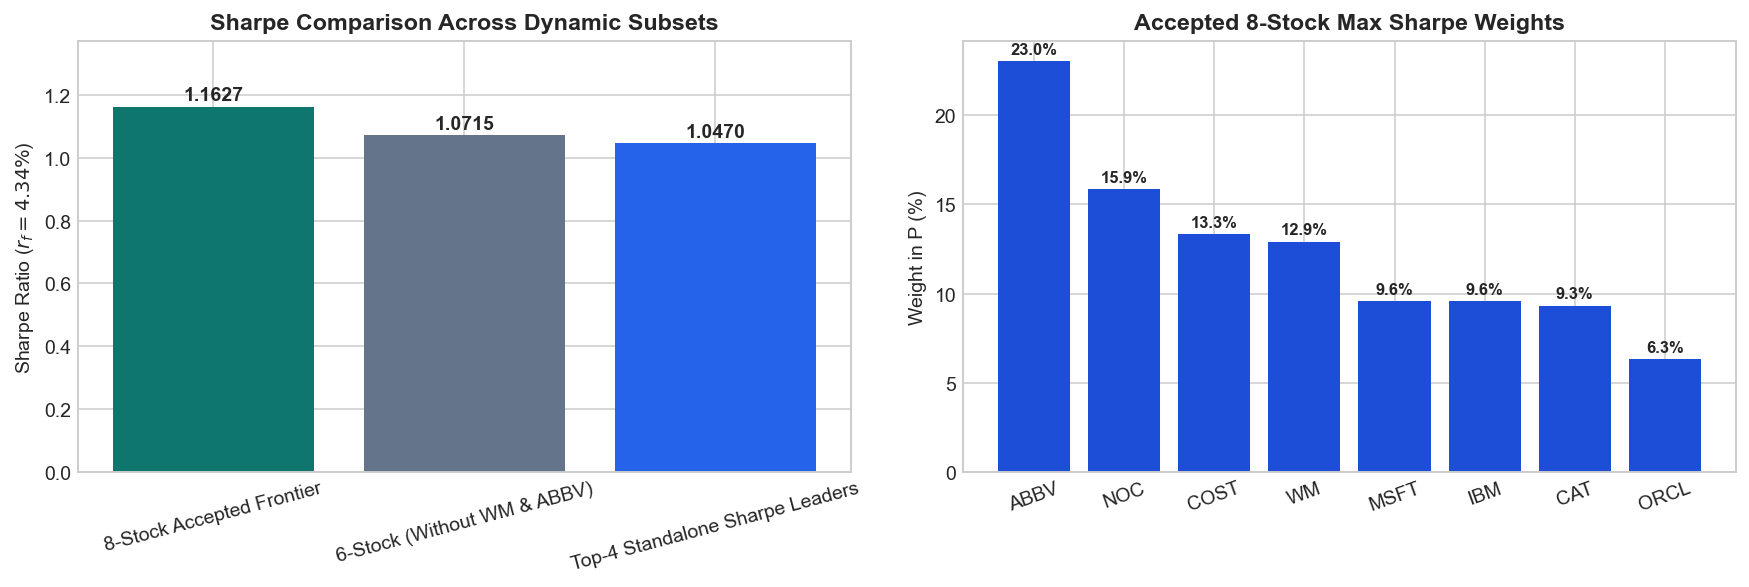

In [13]:
# 3. Draw dynamic Sharpe comparison and accepted P weights
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))  # Create side-by-side two-panel figure
bar_colors = ['#0F766E', '#64748B', '#2563EB'][:len(ablation_df)]
axes[0].bar(ablation_df['Subset'], ablation_df['P Sharpe'], color=bar_colors)  # Plot bar chart on left panel
for i, v in enumerate(ablation_df['P Sharpe']):
    axes[0].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')
axes[0].set(ylabel=rf'Sharpe Ratio ($r_f={rf_screen*100:.2f}\%$)', ylim=(0, max(1.35, ablation_df['P Sharpe'].max() * 1.18)), title='Sharpe Comparison Across Dynamic Subsets')  # Configure left/top panel labels and title
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(SELECTED_TICKERS, wP_sel * 100, color='#1D4ED8')  # Plot bar chart on right panel
for i, v in enumerate(wP_sel * 100):
    axes[1].text(i, v + 0.4, f'{v:.1f}%', ha='center', fontsize=8.5, fontweight='bold')
axes[1].set(ylabel='Weight in P (%)', title=f'Accepted {k_sel}-Stock Max Sharpe Weights')  # Configure right/bottom panel labels and title
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()  # Adjust spacing and render chart